# Group 5's Preminilary Analysis Notebook


#1. Set Up Process

In [289]:
%pip install -q interpret-core==0.7.8

In [290]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings

# Suppress warnings.
warnings.filterwarnings("ignore")
pd.options.mode.chained_assignment = None
pd.options.mode.copy_on_write = True

# All generated files go in this runtime's output folder.
output_folder = Path("eda_outputs")
output_folder.mkdir(exist_ok=True)

In [291]:
from IPython.display import display
from importlib.metadata import version
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.metrics import confusion_matrix, classification_report

output_folder = Path("ebm_outputs")
output_folder.mkdir(exist_ok=True)
print("InterpretML:", version("interpret-core"))

InterpretML: 0.7.8


In [292]:
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import sklearn as sk
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn import svm # SVM
from sklearn.neighbors import KNeighborsClassifier # KNN
from sklearn import metrics # check model accuracy
from sklearn.model_selection import train_test_split  # split data into train & test

In [293]:
import io
import base64
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import HTML, display

## Load the cleaned data



In [294]:
hmda = pd.read_csv("hmda_2025_ny_cleaned.csv", dtype=str)

numeric_columns = ["income", "loan_amount", "tract_minority_population_percent"]
for column in numeric_columns + ["denied", "action_taken"]:
    hmda[column] = pd.to_numeric(hmda[column], errors="raise")

print("Applications:", len(hmda))
print("Denied:", hmda["denied"].sum())
print("Denial rate:", round(hmda["denied"].mean() * 100, 1), "%")
hmda.head()

Applications: 10513
Denied: 1476
Denial rate: 14.0 %


,activity_year,state_code,lei,action_taken,derived_race,derived_ethnicity,applicant_age,loan_type,debt_to_income_ratio,derived_msa-md,...,census_tract,income,loan_amount,tract_minority_population_percent,tract_to_msa_income_percentage,tract_population,denied,age_band,dti_band,tract_minority_band
0,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Not Hispanic or Latino,35-44,1,30%-<36%,28740,...,36111952100,247.0,585000,52.21,68,3687,0,35-44,30%-<36%,40–<60%
1,2025,NY,7H6GLXDRUGQFU57RNE97,1,Joint,Not Hispanic or Latino,35-44,1,30%-<36%,35614,...,36081026902,100.0,305000,95.74,61,4244,0,35-44,30%-<36%,80–100%
2,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Not Hispanic or Latino,25-34,1,30%-<36%,35614,...,36119014701,125.0,225000,42.27,122,4977,0,25-34,30%-<36%,40–<60%
3,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Ethnicity Not Available,35-44,1,39,35614,...,36081092800,245.0,605000,9.14,181,3204,0,35-44,36%-49%,0–<20%
4,2025,NY,7H6GLXDRUGQFU57RNE97,2,White,Hispanic or Latino,35-44,1,30%-<36%,35614,...,36081071304,100.0,85000,46.01,125,6386,0,35-44,30%-<36%,40–<60%


# 3. Choose predictors and split the sample
Race and ethnicity are included with respect to tract minority share to reflect that our study concerns the disparity among racial/ethnic groups and neighborhoods. Income, loan amount, debt-to-income (DTI), loan type, lender, and metro area provide the economic and institutional contexts for each application.

The target variable is denied, derived from action_taken, which represents whether a loan was approved or denied. Therefore, we do not include "action_taken" in this model. We also exclude all outcome dependent variables such as why an applicant was denied a loan.

DTI will be treated as categorical since it is impossible to assign a reasonable midpoint value to many of its ranges. All applicants were included regardless of how they may have been grouped together by specific EDA plots. However, we did retain all of the remaining applications and demographic categories that were omitted based on specific EDA plot requirements.

We randomly sampled 20% of the total number of applications into a test data set and used the remaining 80% of the data to create a training data set. To ensure that the proportion of denied applications would remain relatively consistent between the two datasets, we stratified the sample by application status. To ensure that the same division could be reproduced at any time, we assigned a fixed random seed during sampling.


In [295]:
categorical_columns = ["derived_race", "derived_ethnicity", "dti_band", "loan_type", "lei", "derived_msa-md"]
features = numeric_columns + categorical_columns
X = hmda[features].copy()
y = hmda["denied"].astype(int)

# Preserve unavailable categories instead of dropping applications.
for column in categorical_columns:
    X[column] = X[column].fillna("Missing")

# Nonpositive income cannot be treated as ordinary positive annual income.
X["income_nonpositive"] = (X["income"] <= 0).astype(int)
X["income_unavailable"] = (X["income"].isna() | (X["income"] <= 0)).astype(int)
X.loc[X["income"] <= 0, "income"] = np.nan

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train = X_train.copy()
X_test = X_test.copy()

print("Training applications:", len(X_train))
print("Test applications:", len(X_test))
print("Unavailable/nonpositive income:", int(X["income_unavailable"].sum()))


Training applications: 8410
Test applications: 2103
Unavailable/nonpositive income: 469


## Prepare the variables
I retain all of the fields that we will be using and then convert any numeric fields to appropriate numeric types. Blank, NA (Not Available) and exempted values are treated as missing in each of the relevant fields. I also retain missing demographic information and unusual income information from the sample.

Denial is coded as a 1 for Action 3 and a 0 for Actions 1 and/or 2. Denial as measured here indicates what decision was made on the applicant's submitted application, however it does not indicate why an applicant was denied nor can it demonstrate discriminatory behavior.


In [296]:
numeric_columns = ["income", "loan_amount", "tract_minority_population_percent",
                   "tract_to_msa_income_percentage", "tract_population"]
keep_columns = ["activity_year", "state_code", "lei", "action_taken",
                "derived_race", "derived_ethnicity", "applicant_age",
                "loan_type", "debt_to_income_ratio", "derived_msa-md",
                "county_code", "census_tract"] + numeric_columns
hmda = hmda[keep_columns].copy()

for column in numeric_columns:
    hmda[column] = hmda[column].replace({"": np.nan, "NA": np.nan,
                                       "Exempt": np.nan})
    hmda[column] = pd.to_numeric(hmda[column])

hmda["denied"] = (hmda["action_taken"] == "3").astype(int)
hmda["age_band"] = hmda["applicant_age"].replace({"8888": "Missing"})


DTI combines ranges with discrete values. The range of 36 through 49 is a single band that preserves the original value in the column. Bands are created for missing values (DTI & Age) as well as five tract minority share bands. Tract Composition refers to the neighborhood characteristics of the property. It does not refer to the identity of the applicant.

In [297]:
hmda["dti_band"] = hmda["debt_to_income_ratio"].replace(
    {"": "Missing", "NA": "Missing", "Exempt": "Missing"}
)
exact_dti = [str(value) for value in range(36, 50)]
hmda.loc[hmda["debt_to_income_ratio"].isin(exact_dti), "dti_band"] = "36%-49%"

# Use nonoverlapping intervals
tract_labels = ["0–<20%", "20–<40%", "40–<60%", "60–<80%", "80–100%"]
hmda["tract_minority_band"] = pd.cut(
    hmda["tract_minority_population_percent"],
    bins=[0, 20, 40, 60, 80, np.inf], labels=tract_labels, right=False
).astype("string").fillna("Missing")

hmda.to_csv(output_folder / "hmda_2025_ny_cleaned.csv", index=False)
hmda.head()


,activity_year,state_code,lei,action_taken,derived_race,derived_ethnicity,applicant_age,loan_type,debt_to_income_ratio,derived_msa-md,...,census_tract,income,loan_amount,tract_minority_population_percent,tract_to_msa_income_percentage,tract_population,denied,age_band,dti_band,tract_minority_band
0,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Not Hispanic or Latino,35-44,1,30%-<36%,28740,...,36111952100,247.0,585000,52.21,68,3687,0,35-44,30%-<36%,40–<60%
1,2025,NY,7H6GLXDRUGQFU57RNE97,1,Joint,Not Hispanic or Latino,35-44,1,30%-<36%,35614,...,36081026902,100.0,305000,95.74,61,4244,0,35-44,30%-<36%,80–100%
2,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Not Hispanic or Latino,25-34,1,30%-<36%,35614,...,36119014701,125.0,225000,42.27,122,4977,0,25-34,30%-<36%,40–<60%
3,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Ethnicity Not Available,35-44,1,39,35614,...,36081092800,245.0,605000,9.14,181,3204,0,35-44,36%-49%,0–<20%
4,2025,NY,7H6GLXDRUGQFU57RNE97,2,White,Hispanic or Latino,35-44,1,30%-<36%,35614,...,36081071304,100.0,85000,46.01,125,6386,0,35-44,30%-<36%,40–<60%


**Income** is in thousands of dollars, so 173 means $173,000. There are 395 missing incomes and 74 nonpositive values.


In [298]:
print("Applications:", len(hmda))
print("Denied:", hmda["denied"].sum())
print("Missing income:", hmda["income"].isna().sum())
print("Nonpositive income:", (hmda["income"] <= 0).sum())
print("Missing DTI:", (hmda["dti_band"] == "Missing").sum())
hmda["income"].describe()


Applications: 10513
Denied: 0
Missing income: 395
Nonpositive income: 74
Missing DTI: 0


,income
count,10118.000000
mean,290.685709
std,483.276447
min,-719.000000
25%,106.000000
50%,173.000000
75%,317.000000
max,16328.000000


## Income distribution
A log scale is used here because many of the largest incomes were too big to be shown with a linear scale, making it difficult to see what the smaller incomes look like. This trick may have been discussed in CMPU250, but if not it's a method learned from CMPU366 - NLP. Only the 10,044 positive reported incomes are included for this plot. The 469 missing or non-positive values are still retained as part of the cleaned data.

Alt Text: Logarithmic histogram of annual income (in thousands), only including positive values. Black bars outline blue bars and add black diagonal hatching to allow bar identification in grayscale.

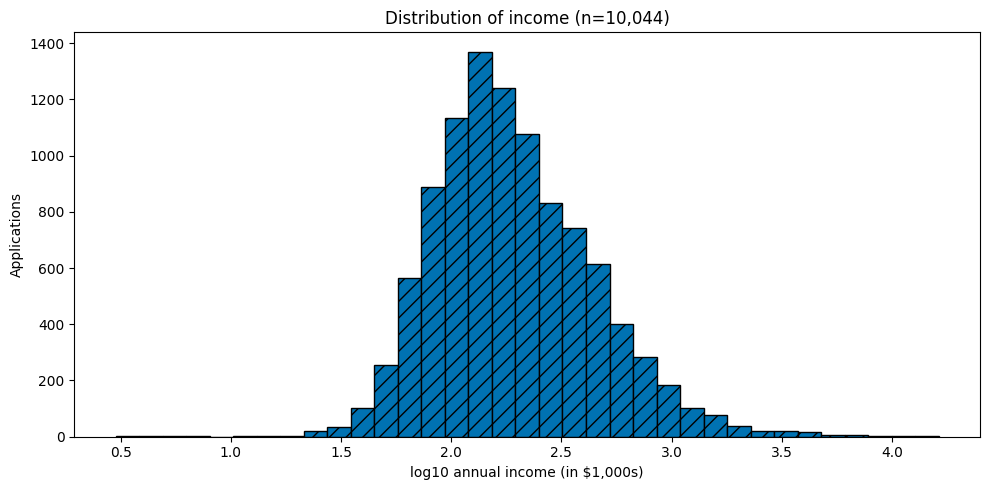

In [299]:
positive_income = hmda.loc[hmda["income"] > 0, "income"]
log_income = np.log10(positive_income)

ax = log_income.plot.hist(bins=35, figsize=(10, 5), color="#0072B2",
                          edgecolor="black", hatch="//")
ax.set_title(f"Distribution of income (n={len(positive_income):,})")
ax.set_xlabel("log10 annual income (in $1,000s)")
ax.set_ylabel("Applications")
plt.tight_layout()
plt.savefig(output_folder / "income_distribution.png", dpi=200,
            bbox_inches="tight")
plt.show()


The reported incomes have a long right tail: the median is roughly $173,000.

The mean is roughly $291,000.

# Creating DTI Categorical Bands

In creating the DTI Categorical bands, I noticed that HMDA reports debt-to-income ratio in a mixed format though ranges for ranges for most values

(e.g. "20%-<30%"). However, it does exact integers from 36 to 49. I used the pre-built `dti_band` column, which puts
36 to 49 into a single band, and set it as an ordered categorical from lowest to highest DTI.
Limitation with this is that since 36-49 is the largest group i miss to see the distribution across each integer there in comparison to the other bands.
The applications with missing DTI are excluded.

In [300]:
#Creating the DTI Bands
dti_order = ["<20%", "20%-<30%", "30%-<36%", "36%-49%", "50%-60%", ">60%"]
hmda["dti_band"] = pd.Categorical(
    hmda["dti_band"].where(hmda["dti_band"].isin(dti_order)),
    categories=dti_order,
    ordered=True,
)

# Cleaning the derived_race column

I excluded "Race Not Available" and "Free Form Text Only" because they don't identify a group.
I also dropped groups with fewer than 100 applications (American Indian or Alaska Native, n=28; Native Hawaiian or Other Pacific Islander, n=25; 2 or more minority races, n=21), because percentages based on so few applications are too unstable to interpret.

This leaves four groups: White, Asian, Black or African American, and Joint. Leaving out the smaller groups is a limitation of this analysis, not evidence that they experience no disparities.

In [301]:
# Filtering out rows with missing race or DTI band. Excluding the "Race Not Available" and "Free Form Text Only" categories.
exclude = ["Race Not Available", "Free Form Text Only"]
plot_df = hmda[hmda["dti_band"].notna() & ~hmda["derived_race"].isin(exclude)]
counts = plot_df["derived_race"].value_counts()
plot_df = plot_df[plot_df["derived_race"].isin(counts[counts >= 100].index)]

### Debt-to-income distribution by applicant race stacked bar chart

This 100% stacked bar chart shows what share of each group's applications falls in each DTI band.
The percentages are calculated within each race, so we can compare groups of different sizes more directly.
A scatter plot wasn't suitable because both variables are categorical.

This chart shows how applicant finances differ by group. This is important because DTI is a major consideration when making lending decisions. It could explain part of any difference in denial rates.

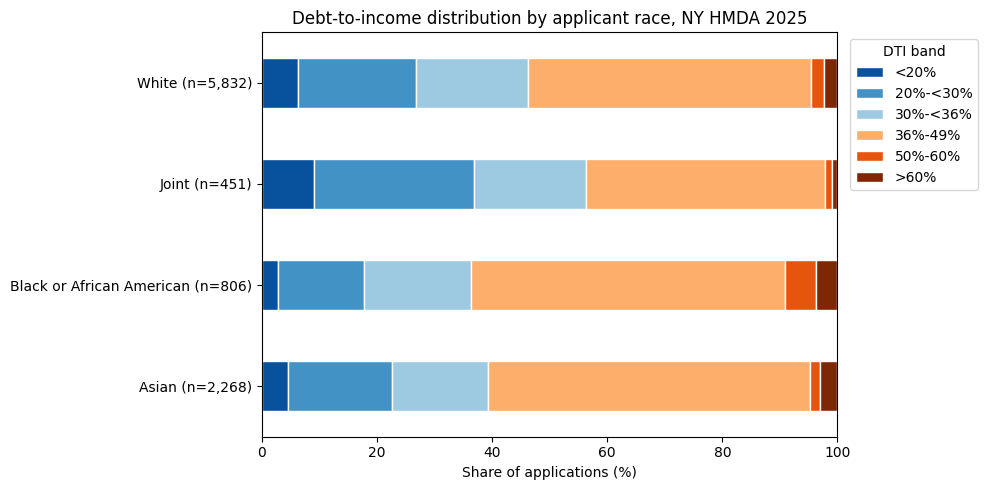

In [302]:
# Filtering out rows with missing race or DTI band. Excluding the "Race Not Available" and "Free Form Text Only" categories.
exclude = ["Race Not Available", "Free Form Text Only"]
plot_df = hmda[hmda["dti_band"].notna() & ~hmda["derived_race"].isin(exclude)]
counts = plot_df["derived_race"].value_counts()
plot_df = plot_df[plot_df["derived_race"].isin(counts[counts >= 100].index)]

# Chart 1: DTI distribution by race
tab = pd.crosstab(plot_df["derived_race"], plot_df["dti_band"], normalize="index") * 100
n = plot_df["derived_race"].value_counts()
tab.index = [f"{r} (n={n[r]:,})" for r in tab.index]

# Plotting the stacked bar chart with a an accessible colour palette
dti_colors = ["#08519c", "#4292c6", "#9ecae1", "#fdae6b", "#e6550d", "#7f2704"]

ax = tab.plot(kind="barh", stacked=True, figsize=(10, 5),
              color=dti_colors, edgecolor="white", linewidth=1)
ax.set_xlabel("Share of applications (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_title("Debt-to-income distribution by applicant race, NY HMDA 2025")
ax.legend(title="DTI band", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("dti_by_race.png", dpi=200)

def show_with_alt(alt, dpi=150):
    buf = io.BytesIO()
    plt.savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close()
    img64 = base64.b64encode(buf.getvalue()).decode()

    show_with_alt(
    "Stacked bar chart of debt-to-income (DTI) ratio bands for New York 2025 HMDA "
    "mortgage applications by applicant race. Black applicants have the largest share "
    "of high DTI applications, with about 9% above 50% DTI versus roughly 2% to 5% for "
    "other groups. Joint applicants have the most low DTI applications, with about 56% "
    "under 36%."
)

    display(HTML(f'<img src="data:image/png;base64,{img64}" alt="{alt}" style="max-width:100%">'))

**Chart description:**

Horizontal 100% stacked bar chart titled "Debt-to-income distribution by applicant race, NY HMDA 2025." Each bar shows the share of applications in six DTI bands: under 20%, 20% to under 30%, 30% to under 36%, 36% to 49%, 50% to 60%, and over 60%. Colors run from dark green (low DTI) to dark red (high DTI).

Approximate (not exact) values:

- White (n=5,832): 6%, 21%, 19%, 49%, 2%, 2%. About 46% under 36% DTI.
- Joint (n=451): 9%, 28%, 19%, 42%, 1%, 1%. About 56% under 36% DTI.
- Black or African American (n=806): 3%, 15%, 18%, 55%, 5%, 4%. About 36% under 36% DTI.
- Asian (n=2,268): 4%, 18%, 17%, 56%, 2%, 3%. About 40% under 36% DTI.

For every group, the 36% to 49% band is the largest.

# Denial rate by tract minority share using a bar plot

I used seaborn’s barplot, which estimates a 95% confidence interval by (drawing out repeated samples with replacement from original data). It did the resampling of the data 1,000 times; taking the 2.5th and 97.5th percentiles of the resampled denial rates.

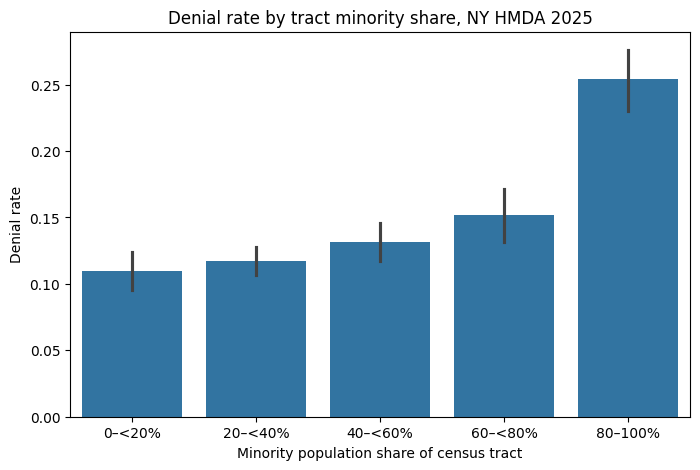


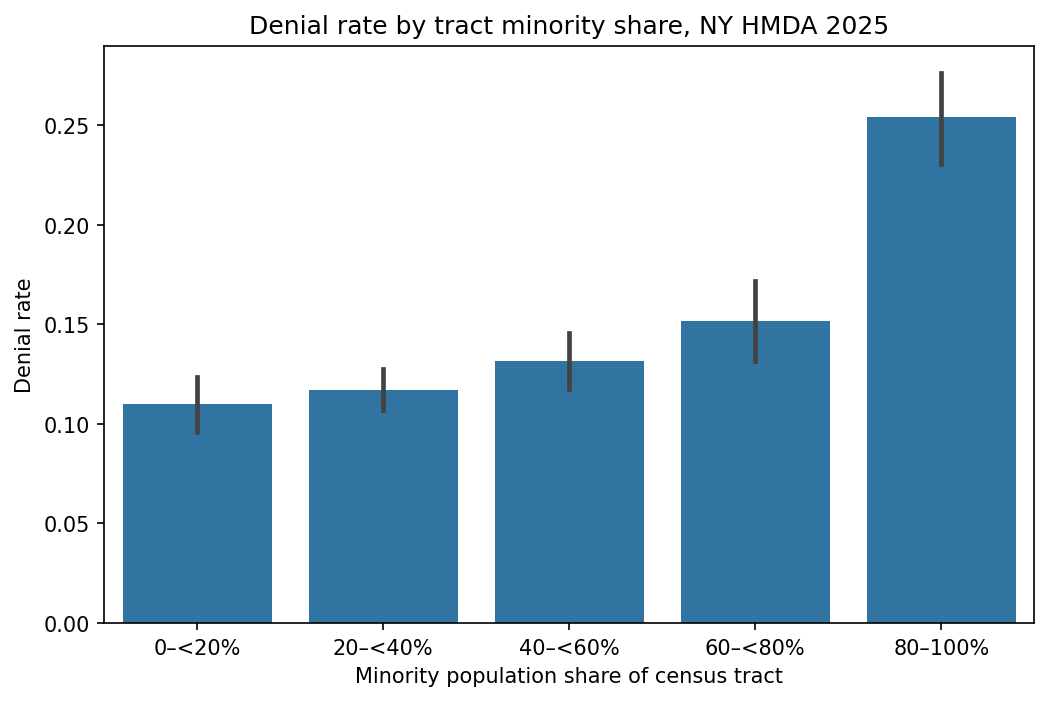

In [303]:
# Recalculate 'denied' based on action_taken being numeric (3 is Denied)
hmda["denied"] = (hmda["action_taken"].astype(float) == 3).astype(int)

fig, ax = plt.subplots(figsize=(8, 5))

order = ["0–<20%", "20–<40%", "40–<60%", "60–<80%", "80–100%"]
sns.barplot(data=hmda, x="tract_minority_band", y="denied", order=order, errorbar=("ci", 95), ax=ax)
ax.set_xlabel("Minority population share of census tract")
ax.set_ylabel("Denial rate")
ax.set_title("Denial rate by tract minority share, NY HMDA 2025")

# Save for base64 HTML embedding (accessibility alt text)
buf = io.BytesIO()
plt.savefig(buf, format="png", dpi=150, bbox_inches="tight")
img64 = base64.b64encode(buf.getvalue()).decode()

# Show the plot directly in the notebook
plt.show()

alt = ("Bar chart of mortgage denial rates by the minority population share of the "
       "applicant's census tract, NY HMDA 2025. Denial rates rise gradually from about "
       "11% in tracts under 20% minority to about 15% in tracts 60% to 80% minority, "
       "then jump to about 25% in tracts 80% to 100% minority.")

display(HTML(f'<p><strong>Accessible Image Markup:</strong></p><img src="data:image/png;base64,{img64}" alt="{alt}" style="max-width:100%">'))

**Chart description:** Bar chart titled "Denial rate by tract minority share, NY HMDA 2025." The x-axis shows five bands of census tract minority population share; the y-axis shows denial rate. Error bars show 95% confidence intervals. Approximate values:

- 0% to under 20%: about 11%
- 20% to under 40%: about 12%
- 40% to under 60%: about 13%
- 60% to under 80%: about 15%
- 80% to 100%: about 25%

The increase is modest across the first four bands, with overlapping error bars between neighbors. The 80% to 100% band stands apart, with a rate more than double the lowest band and no overlap with any other band.

In [304]:
# @title Checking Trends In Application Approval and Denial

**Application status distribution across various races**

I ran 8920 out of 10513 rows because the 15% of the rows dropped had "Race not Available" and "Joint" applicants. This missing data may be correlated with the application channels.


The groups appear uneven with white applicants being the majority at 5,841 followed by Asian 2271 and only 808 Black. This shows an uneven utilization of the mortagage resources with black people having the lowest applicants noted.


From the latest population data of New York state the population of Black or African Americans (14.8 % to 17.6%) is higher than the Asian population (8.6% to 9.6%). This made us question why it didn't translate to the mortgage applications.

Kept 8,920 of 10,513 rows
derived_race
White                        5841
Asian                        2271
Black or African American     808
Name: count, dtype: int64


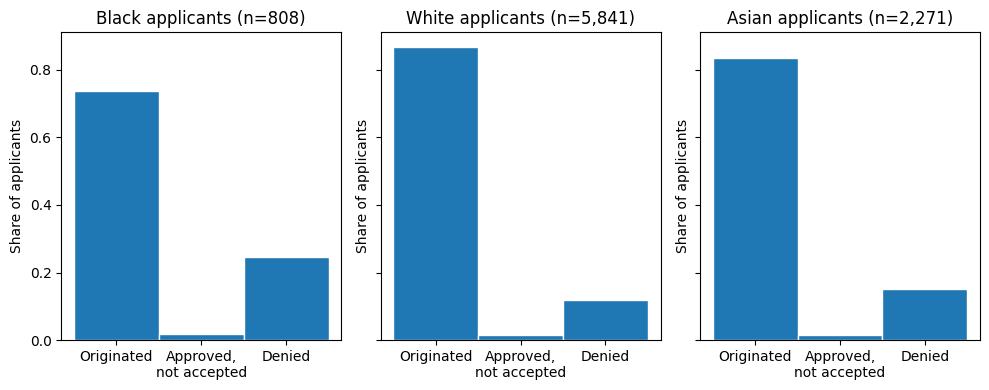

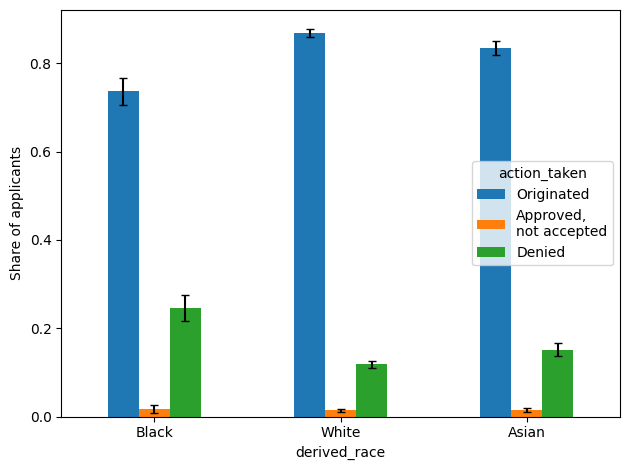

action_taken  Originated  Approved,\nnot accepted  Denied
derived_race                                             
Black              0.736                    0.017   0.246
White              0.868                    0.014   0.118
Asian              0.835                    0.014   0.151


In [305]:
hmda["action_taken"] = pd.to_numeric(hmda["action_taken"])
hmda = hmda[hmda["action_taken"].isin([1, 2, 3])]

labels = {1: "Originated", 2: "Approved,\nnot accepted", 3: "Denied"}
groups = {"Black" : "Black or African American", "White" : "White", "Asian": "Asian"}

d = hmda[hmda["derived_race"].isin(groups.values())]
print(f"Kept {len(d):,} of {len(hmda):,} rows")
print(d["derived_race"].value_counts())


# 1) Two histograms, one per group, bins centred on 1, 2, 3, as shares
bins = np.arange(0.5, 4.5, 1)
fig, axes = plt.subplots(1, 3, figsize=(10, 4), sharey = True)
for ax, (name, race) in zip(axes, groups.items()):
    s = d.loc[d["derived_race"] == race, "action_taken"]
    ax.hist(s, bins=bins, weights=np.ones(len(s)) / len(s), edgecolor="white")
    ax.set_xticks([1, 2, 3]); ax.set_xticklabels(labels.values())
    ax.set_title(f"{name} applicants (n={len(s):,})")
    ax.set_ylabel("Share of applicants")
axes[0].set_ylabel("Share of applicants")
plt.tight_layout(); plt.show()

inv = {v: k for k, v in groups.items()}
counts = d.groupby("derived_race")["action_taken"].value_counts().unstack()
n = counts.sum(axis=1)
p = counts.div(n, axis=0)
se = np.sqrt(p * (1 - p)).div(np.sqrt(n), axis=0)

p = p.rename(index=inv, columns=labels).loc[list(groups)]
se = se.rename(index=inv, columns=labels).loc[list(groups)]
p.plot.bar(yerr=1.96 * se, capsize=3, rot=0)
plt.ylabel("Share of applicants"); plt.tight_layout(); plt.show()

print(p.round(3))

Since we still couldn't conlusively show the difference is unfair clearly from the graphs above, in this next step we fit a logistic regression for denial with race and use various controls

#Logistic Regression

In [310]:
# keep three groups and applicants with usable income
hmda = hmda[hmda["derived_race"].isin(["White", "Black or African American", "Asian"])]
hmda = hmda[hmda["income"] > 0].copy() # ensure income is >0 and remove missing and NaN values.

hmda["denied"] = (hmda["action_taken"] == 3).astype(int)      # 1 and 2 = not denied
hmda["race"] = hmda["derived_race"].replace({"Black or African American": "Black"})

hmda["log_income"] = np.log(hmda["income"])
hmda["log_loan"] = np.log(hmda["loan_amount"])

race = "C(race, Treatment('White'))"                      # White = comparison group
controls = "log_income + log_loan + C(dti_band) + C(age_band) + C(loan_type) + C(lei)"

m1 = smf.logit(f"denied ~ {race}", hmda).fit(disp=0, method="bfgs", maxiter=1000)
m2 = smf.logit(f"denied ~ {race} + {controls}", hmda).fit(disp=0, method="bfgs", maxiter=1000)

def odds_ratios(model):
    t = np.exp(pd.concat([model.params, model.conf_int()], axis=1))
    t.columns = ["odds_ratio", "ci_low", "ci_high"]
    return t[t.index.str.contains("race")].round(2)

print("Race only:\n", odds_ratios(m1))
print("\nWith controls:\n", odds_ratios(m2))

Race only:
                                       odds_ratio  ci_low  ci_high
C(race, Treatment('White'))[T.Asian]        1.32    1.15     1.53
C(race, Treatment('White'))[T.Black]        2.45    2.04     2.94

With controls:
                                       odds_ratio  ci_low  ci_high
C(race, Treatment('White'))[T.Asian]        1.47    1.23     1.74
C(race, Treatment('White'))[T.Black]        1.74    1.39     2.18


Using White as the baseline:

Black applicants were denied at roughly twice (2.45) the White rate, and even after controlling for income, loan amount, DTI, age, loan type and lender, they had about 1.74 times the odds of denial.

Asians were 1.32 times more likely to be denied than the White which is moderate compared to the rates I saw with Asians. After controlling for income, loan amount, DTI, age, loan type and lender, they had about 1.47 times the odds of denial. This is a rise from the 1.32 which is suprising. This suggests that Asian applicants may look better on paper in some respect, such as that they apply for larger loans or have higher income, or they apply to lenders with lower denial rates.

Though the rates seen in black applicants are high, the absence of credit scores means this cannot be attributed to discrimination alone.

#The Ethnicity + Tract Minority% + MSA Regression

I analyzed ethnicity separately instead of adding it to the race model because Hispanic ethnicity overlaps heavily with race in this data (most Hispanic applicants are classified as White, with only 82 Black and 16 Asian Hispanic applicants)

Including both would leave too few applicants in some groups to estimate their effects separately, and keeping the analyses apart lets each one answer a single question.

In [307]:
# keep Hispanic vs. Not Hispanic applicants with usable income
hmda_regressed_2 = hmda[hmda["derived_ethnicity"].isin(["Not Hispanic or Latino", "Hispanic or Latino"])]
hmda_regressed_2 = hmda[hmda["income"] > 0].copy()

hmda_regressed_2["denied"] = (hmda_regressed_2["action_taken"] == 3).astype(int)               # 1 = denied
hmda_regressed_2["hispanic"] = (hmda_regressed_2["derived_ethnicity"] == "Hispanic or Latino").astype(int)
hmda_regressed_2["tract_minority_10"] = hmda_regressed_2["tract_minority_population_percent"] / 10   # effect per 10 points
hmda_regressed_2["log_income"] = np.log(hmda_regressed_2["income"])
hmda_regressed_2["log_loan"] = np.log(hmda_regressed_2["loan_amount"])

# MSAs with fewer than 100 applicants are too small to estimate, so group them
msa = hmda_regressed_2["derived_msa-md"].astype(str)
hmda_regressed_2["msa"] = msa.where(msa.map(msa.value_counts()) >= 100, "Other")

msa_term = "C(msa, Treatment('35614'))"                            # 35614 = NYC metro, the largest
controls = "log_income + log_loan + C(dti_band) + C(age_band) + C(loan_type) + C(lei)"

fit = lambda f: smf.logit(f, hmda_regressed_2).fit(disp=0, method="bfgs", maxiter=1000)
m1 = fit("denied ~ hispanic")
m2 = fit(f"denied ~ hispanic + tract_minority_10 + {msa_term}")
m3 = fit(f"denied ~ hispanic + tract_minority_10 + {msa_term} + {controls}")

def odds_ratios(model):
    t = np.exp(pd.concat([model.params, model.conf_int()], axis=1))
    t.columns = ["odds_ratio", "ci_low", "ci_high"]
    return t.loc[t.index.isin(["hispanic", "tract_minority_10"])].round(2)

print("1. Ethnicity only:\n", odds_ratios(m1))
print("\n2. + tract minority % and MSA:\n", odds_ratios(m2))
print("\n3. + applicant controls:\n", odds_ratios(m3))

1. Ethnicity only:
           odds_ratio  ci_low  ci_high
hispanic        1.73    1.42     2.11

2. + tract minority % and MSA:
                    odds_ratio  ci_low  ci_high
hispanic                 1.43    1.17     1.75
tract_minority_10        1.15    1.12     1.18

3. + applicant controls:
                    odds_ratio  ci_low  ci_high
hispanic                 1.16    0.92     1.48
tract_minority_10        1.11    1.08     1.15


# The Race + Tract Minority % + MSA Regression
**Goal**. This regression tests whether an applicant's race is associated with mortgage denial after accounting for where the applicant is applying. I compare White, Black and Asian applicants, with White applicants as the baseline, and the outcome is whether the application was denied (action_taken = 3) versus approved or originated (1 and 2).

**Method :** I use logistic regression and report odds ratios with 95% confidence intervals. An odds ratio above 1 means higher odds of denial than White applicants. I fit two models. Model 1 adds neighborhood context: the minority share of the applicant's census tract (per 10 points) and the metropolitan area (MSA). Model 2 adds applicant controls: income, loan amount, debt-to-income band, age band, loan type and lender.

In [308]:
hmda_regressed_3 = hmda[hmda["derived_race"].isin(["White", "Black or African American", "Asian"])]
hmda_regressed_3 = hmda[hmda ["income"] > 0].copy()

hmda_regressed_3["denied"] = (hmda_regressed_3["action_taken"] == 3).astype(int)   # 1 = denied
hmda_regressed_3["race"] = hmda_regressed_3["derived_race"].replace({"Black or African American": "Black"})
hmda_regressed_3["tract_minority_10"] = hmda_regressed_3["tract_minority_population_percent"] / 10   # effect per 10 points
hmda_regressed_3["log_income"] = np.log(hmda_regressed_3["income"])
hmda_regressed_3["log_loan"] = np.log(hmda_regressed_3["loan_amount"])

# MSAs with fewer than 100 applicants are too small to estimate, so group them
msa = hmda_regressed_3["derived_msa-md"].astype(str)
hmda_regressed_3["msa"] = msa.where(msa.map(msa.value_counts()) >= 100, "Other")

race = "C(race, Treatment('White'))"
msa_term = "C(msa, Treatment('35614'))"                            # 35614 = NYC metro, the largest
controls = "log_income + log_loan + C(dti_band) + C(age_band) + C(loan_type) + C(lei)"

fit = lambda f: smf.logit(f, hmda_regressed_3).fit(disp=0, method="bfgs", maxiter=1000)
m1 = fit(f"denied ~ {race} + tract_minority_10 + {msa_term}")
m2 = fit(f"denied ~ {race} + tract_minority_10 + {msa_term} + {controls}")

def odds_ratios(model):
    t = np.exp(pd.concat([model.params, model.conf_int()], axis=1))
    t.columns = ["odds_ratio", "ci_low", "ci_high"]
    t.index = t.index.str.replace(r"C\(race.*\)\[T\.(\w+)\]", r"race: \1", regex=True)
    return t.loc[t.index.str.startswith("race") | (t.index == "tract_minority_10")].round(2)

print("1. Race + tract minority % + MSA:\n", odds_ratios(m1))
print("\n2. + applicant controls:\n", odds_ratios(m2))
print("\nRows used:", len(hmda_regressed_3))

1. Race + tract minority % + MSA:
                    odds_ratio  ci_low  ci_high
race: Asian              1.12    0.96     1.30
race: Black              1.68    1.37     2.07
tract_minority_10        1.13    1.10     1.16

2. + applicant controls:
                    odds_ratio  ci_low  ci_high
race: Asian              1.17    0.98     1.41
race: Black              1.29    1.01     1.64
tract_minority_10        1.10    1.06     1.14

Rows used: 8529


**Conclusion and comments**

Comparing raw denial rates by race can't separate discrimination from differences in applicants' finances or location. Adding controls step by step shows how much of the gap remains once those differences are accounted for. I keep MSA as a categorical variable, since MSA codes are labels and not quantities, and I group MSAs with fewer than 100 applicants into “Other” because their estimates would be too unstable.

#Save the results
This cell is for saving the results. change the bool to True to save/download to your computer a zip.

In [309]:
import shutil
from pathlib import Path

save_results = False

if save_results:
    archive = shutil.make_archive("eda_results", "zip", output_folder)
    try:
        from google.colab import files   # only available in Colab
        files.download(archive)
    except ImportError:
        print(f"Saved to: {Path(archive).resolve()}")